Logistic regression using scikit-learn

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

X = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y = np.array([0, 0, 0, 1, 1, 1])

In [5]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression()
lr_model.fit(X, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [8]:
y_pred = lr_model.predict(X)

print("Prediction on training set:", y_pred)

Prediction on training set: [0 0 0 1 1 1]


In [9]:
print("Accuracy on training set:", lr_model.score(X, y))

Accuracy on training set: 1.0


Visualizacao dos dados

X (features):
 [[0.5 1.5]
 [1.  1. ]
 [1.5 0.5]
 [3.  0.5]
 [2.  2. ]
 [1.  2.5]]

y (classes):
 [0 0 0 1 1 1]


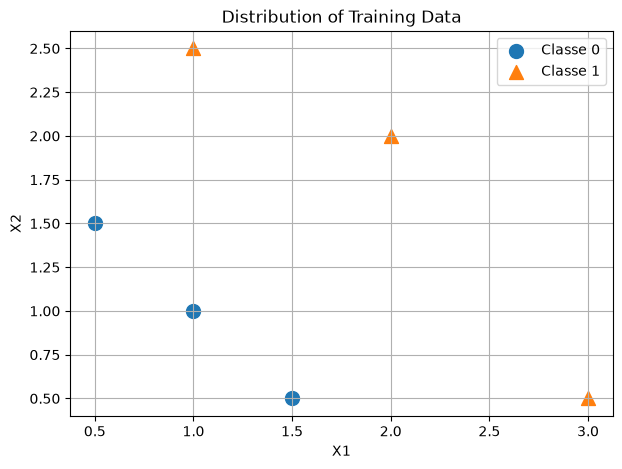

In [10]:
print("X (features):\n", X)
print("\ny (classes):\n", y)

# Gráfico de dispersão
plt.figure(figsize=(7, 5))

plt.scatter(X[y == 0, 0], X[y == 0, 1],
            label="Classe 0", marker="o", s=100)

plt.scatter(X[y == 1, 0], X[y == 1, 1],
            label="Classe 1", marker="^", s=100)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Distribution of Training Data")
plt.legend()
plt.grid()
plt.show()

In [ ]:
lr_model = LogisticRegression(C=1, max_iter=1000)

#C aqui como parametro representa a regularizacao, 1 eh o valor padrao

lr_model.fit(X, y)

print("Weights:", lr_model.coef_)
print("Bias:", lr_model.intercept_)

Weights: [[0.01489569 0.00997832]]
Bias: [-0.03571293]


Visualizar fronteira de decisao

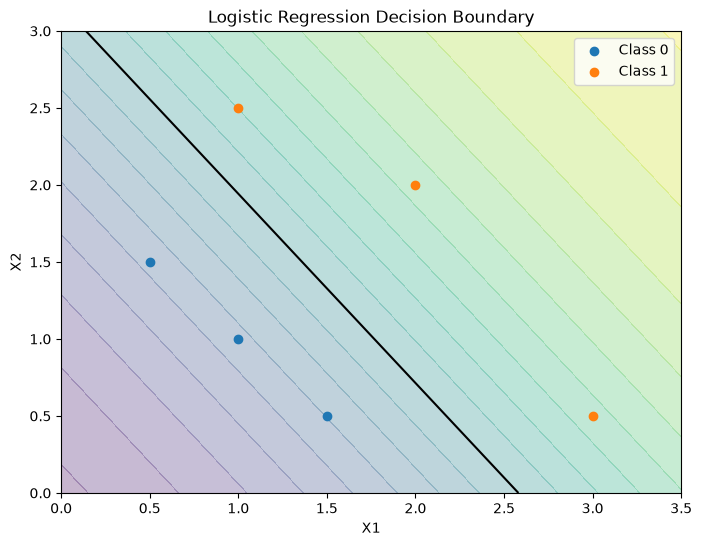

In [12]:
# Criando uma grade de coordenadas
x1 = np.linspace(X[:, 0].min() - 0.5,
                 X[:, 0].max() + 0.5, 200)

x2 = np.linspace(X[:, 1].min() - 0.5,
                 X[:, 1].max() + 0.5, 200)

xx1, xx2 = np.meshgrid(x1, x2)

# Preparando os dados para previsão
grid = np.c_[xx1.ravel(), xx2.ravel()]

# Probabilidade prevista para classe 1
probs = lr_model.predict_proba(grid)[:, 1]
probs = probs.reshape(xx1.shape)

# Visualização
plt.figure(figsize=(8, 6))

plt.contourf(xx1, xx2, probs, levels=20, alpha=0.3)
plt.contour(xx1, xx2, probs, levels=[0.5], colors="black")

plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Class 1")

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.show()

Utilizando graus polinomiais

In [13]:
degree = 2

lr_model = make_pipeline(
    PolynomialFeatures(degree=degree, include_bias=False),
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000)
)

lr_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomialfeatures', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'



===== DEGREE 1 =====
Features: ['x1' 'x2']
Coefficients: [[0.96127078 0.79228194]]
Intercept: [0.00765516]
Iterations: [6]

===== DEGREE 2 =====
Features: ['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']
Coefficients: [[0.59474454 0.40425038 0.60730186 0.61999019 0.52088337]]
Intercept: [0.05829567]
Iterations: [7]

===== DEGREE 3 =====
Features: ['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2' 'x1^3' 'x1^2 x2' 'x1 x2^2' 'x2^3']
Coefficients: [[0.41906504 0.25793516 0.43337013 0.39703153 0.34375189 0.43853987
  0.40134656 0.35133651 0.39639788]]
Intercept: [0.11299867]
Iterations: [8]


C:\Users\Joao Vitor\AppData\Local\Temp\ipykernel_35888\3533589165.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


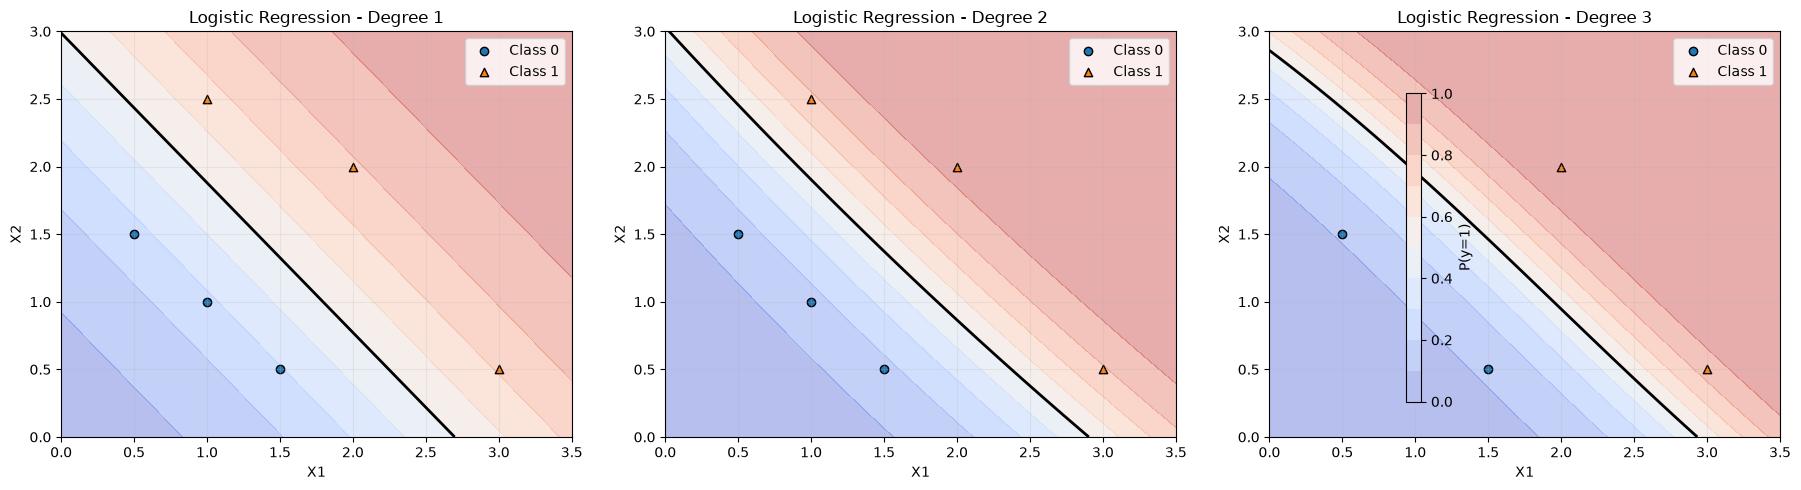

In [14]:



# Hiperparâmetros ajustáveis
C = 1.0
degrees = [1, 2, 3]

# Criando a grade de pontos para visualizar as fronteiras
x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 300),
    np.linspace(x2_min, x2_max, 300)
)

grid = np.c_[xx1.ravel(), xx2.ravel()]

# Criando os gráficos
fig, axes = plt.subplots(
    1, len(degrees),
    figsize=(6 * len(degrees), 5),
    squeeze=False
)

axes = axes.ravel()

for degree, ax in zip(degrees, axes):

    # Modelo com transformação polinomial
    model = make_pipeline(
        PolynomialFeatures(
            degree=degree,
            include_bias=False
        ),
        StandardScaler(),
        LogisticRegression(
            C=C,
            max_iter=1000
        )
    )

    # Treinamento
    model.fit(X, y)

    # Probabilidades previstas
    probabilities = model.predict_proba(grid)[:, 1]
    probabilities = probabilities.reshape(xx1.shape)

    # Fronteira e regiões de decisão
    contour = ax.contourf(
        xx1, xx2, probabilities,
        levels=np.linspace(0, 1, 11),
        cmap="coolwarm",
        alpha=0.4
    )

    # Fronteira P(y=1) = 0.5
    ax.contour(
        xx1, xx2, probabilities,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    # Dados originais
    ax.scatter(
        X[y == 0, 0], X[y == 0, 1],
        marker="o", label="Class 0",
        edgecolors="black"
    )

    ax.scatter(
        X[y == 1, 0], X[y == 1, 1],
        marker="^", label="Class 1",
        edgecolors="black"
    )

    ax.set_title(f"Logistic Regression - Degree {degree}")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend()
    ax.grid(alpha=0.2)

    # Exibindo os parâmetros aprendidos
    poly = model.named_steps["polynomialfeatures"]
    lr = model.named_steps["logisticregression"]

    print(f"\n===== DEGREE {degree} =====")
    print("Features:", poly.get_feature_names_out(["x1", "x2"]))
    print("Coefficients:", lr.coef_)
    print("Intercept:", lr.intercept_)
    print("Iterations:", lr.n_iter_)

fig.colorbar(
    contour,
    ax=axes.tolist(),
    label="P(y=1)",
    shrink=0.8
)

plt.tight_layout()
plt.show()
